# Brain Tumor Detection and Multi-Class Classification Using Deep Learning
## Phase 1: Classification

**Goal:** Build a CNN that takes a brain MRI image and predicts one of four classes:

| Class | Meaning |
|---|---|
| `glioma` | Glioma tumor |
| `meningioma` | Meningioma tumor |
| `pituitary` | Pituitary tumor |
| `no_tumor` | No tumor |

A single 4-class CNN performs both **tumor detection** (tumor / no tumor) and **tumor type classification**.

**Scope of this phase:** classification only. Segmentation will be added in a later phase as a separate component, so the CNN here is kept fully independent of it.

> **Disclaimer:** This is an academic project for educational purposes. It is NOT a medical diagnosis tool and must not replace a qualified doctor or radiologist.

## 2. Import Libraries

In [1]:
import os
import json
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


## 3. Define Dataset Paths

All configuration lives in one cell. The class order below defines the label mapping (`glioma=0, meningioma=1, pituitary=2, no_tumor=3`) and is reused everywhere (training, evaluation, prediction, saved metadata).

Set `FORCE_RETRAIN = True` to retrain even if a saved model already exists.

In [4]:
# ---------- Paths ----------
DATASET_DIR = "dataset"
TRAIN_DIR = os.path.join(DATASET_DIR, "Training")
TEST_DIR = os.path.join(DATASET_DIR, "Testing")

MODEL_DIR = "models"
RESULTS_DIR = "results"
MODEL_PATH = os.path.join(MODEL_DIR, "brain_tumor_cnn.keras")
CLASS_NAMES_PATH = os.path.join(MODEL_DIR, "class_names.json")
HISTORY_PATH = os.path.join(RESULTS_DIR, "training_history.csv")

# ---------- Settings ----------
SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 20
VAL_SPLIT = 0.2
FORCE_RETRAIN = False

# ---------- Fixed class order (label mapping) ----------
CLASS_NAMES = [
    "glioma_tumor",
    "meningioma_tumor",
    "no_tumor",
    "pituitary_tumor"
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
DISPLAY_NAMES = {
    "glioma_tumor": "Glioma",
    "meningioma_tumor": "Meningioma",
    "pituitary_tumor": "Pituitary",
    "no_tumor": "No Tumor",
}
NUM_CLASSES = len(CLASS_NAMES)
VALID_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")

# ---------- Reproducibility ----------
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---------- Output directories ----------
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# ---------- Check dataset paths ----------
for path in (TRAIN_DIR, TEST_DIR):
    if not os.path.isdir(path):
        raise FileNotFoundError(
            f"Dataset folder not found: '{path}'. "
            "Place the dataset in 'dataset/Training' and 'dataset/Testing', "
            "or change DATASET_DIR above."
        )
    for cls in CLASS_NAMES:
        if not os.path.isdir(os.path.join(path, cls)):
            raise FileNotFoundError(f"Missing class folder: '{os.path.join(path, cls)}'")

print("Dataset paths OK.")
print("Label mapping:", CLASS_TO_IDX)

Dataset paths OK.
Label mapping: {'glioma_tumor': 0, 'meningioma_tumor': 1, 'no_tumor': 2, 'pituitary_tumor': 3}


## 4. Explore Dataset

We list every image file into a table (path, class, label). Each image is also checked with Pillow, and unreadable/corrupt files are excluded so they cannot crash training. Nothing on disk is modified.

In [5]:
def build_dataframe(root_dir):
    """List all image files under root_dir/<class>/ into a DataFrame."""
    rows = []
    for cls in CLASS_NAMES:
        folder = os.path.join(root_dir, cls)
        for fname in sorted(os.listdir(folder)):
            if fname.lower().endswith(VALID_EXT):
                rows.append({
                    "path": os.path.join(folder, fname),
                    "class_name": cls,
                    "label": CLASS_TO_IDX[cls],
                })
    return pd.DataFrame(rows)


def drop_invalid_images(df):
    """Remove files Pillow cannot open. Returns (clean_df, list_of_bad_paths)."""
    bad = []
    for p in df["path"]:
        try:
            with Image.open(p) as im:
                im.verify()
        except Exception:
            bad.append(p)
    return df[~df["path"].isin(bad)].reset_index(drop=True), bad


train_full_df, bad_train = drop_invalid_images(build_dataframe(TRAIN_DIR))
test_df, bad_test = drop_invalid_images(build_dataframe(TEST_DIR))

print("Class names:", CLASS_NAMES)
print(f"Training images (valid): {len(train_full_df)}")
print(f"Testing images  (valid): {len(test_df)}")
print(f"Invalid images skipped:  {len(bad_train)} (train), {len(bad_test)} (test)")
for p in bad_train + bad_test:
    print("  skipped:", p)

if len(train_full_df) == 0 or len(test_df) == 0:
    raise RuntimeError("No valid images found. Check the dataset folders.")

Class names: ['glioma_tumor', 'meningioma_tumor', 'no_tumor', 'pituitary_tumor']
Training images (valid): 2870
Testing images  (valid): 394
Invalid images skipped:  0 (train), 0 (test)


## 5. Display Sample MRI Images

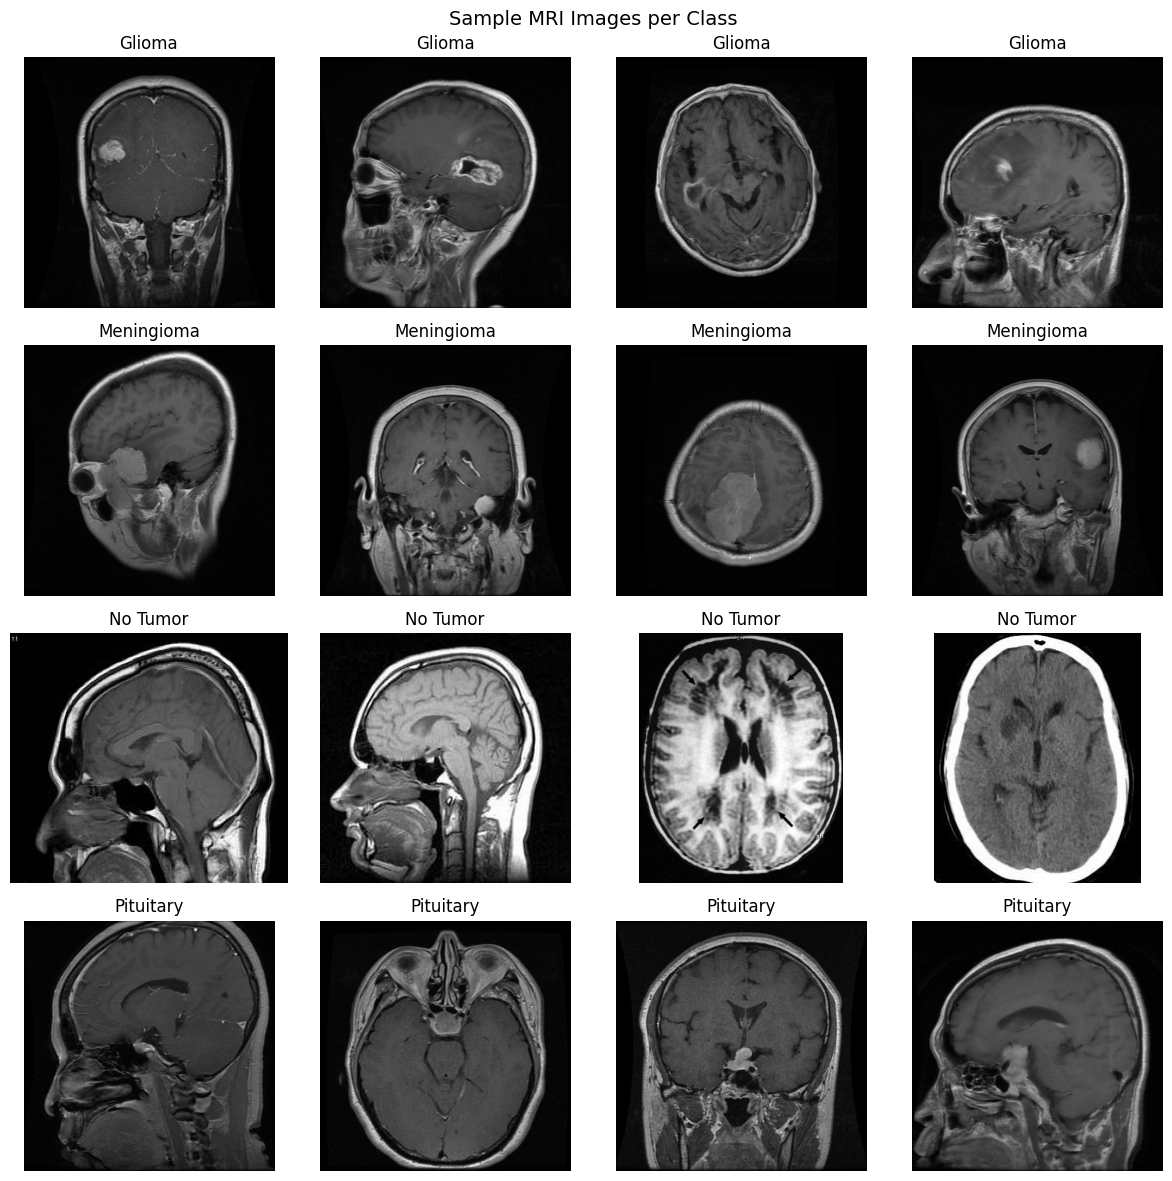

Distinct (height, width) sizes in a 100-image sample: [(216, 234), (218, 236), (225, 225), (236, 212), (236, 236), (240, 210), (241, 230), (252, 200), (309, 236), (315, 315)] ...


In [6]:
SAMPLES_PER_CLASS = 4
fig, axes = plt.subplots(NUM_CLASSES, SAMPLES_PER_CLASS, figsize=(12, 12))

for r, cls in enumerate(CLASS_NAMES):
    paths = train_full_df[train_full_df["class_name"] == cls]["path"]
    chosen = paths.sample(min(SAMPLES_PER_CLASS, len(paths)), random_state=SEED)
    for c in range(SAMPLES_PER_CLASS):
        ax = axes[r, c]
        ax.axis("off")
        if c < len(chosen):
            img = cv2.imread(chosen.iloc[c])
            if img is None:
                continue
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            ax.set_title(DISPLAY_NAMES[cls])

plt.suptitle("Sample MRI Images per Class", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "sample_images.png"), dpi=120)
plt.show()

# Image dimensions (quick check on a small random sample)
sizes = set()
for p in train_full_df["path"].sample(min(100, len(train_full_df)), random_state=SEED):
    img = cv2.imread(p)
    if img is not None:
        sizes.add(img.shape[:2])
print("Distinct (height, width) sizes in a 100-image sample:", sorted(sizes)[:10],
      "..." if len(sizes) > 10 else "")

## 6. Check Class Distribution

            Training  Testing
Glioma           826      100
Meningioma       822      115
No Tumor         395      105
Pituitary        827       74


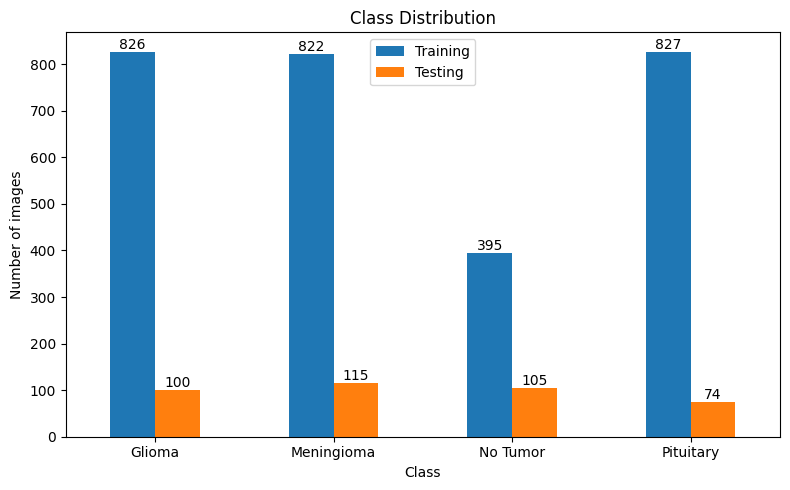

In [7]:
dist = pd.DataFrame({
    "Training": train_full_df["class_name"].value_counts(),
    "Testing": test_df["class_name"].value_counts(),
}).reindex(CLASS_NAMES).fillna(0).astype(int)
dist.index = [DISPLAY_NAMES[c] for c in dist.index]
print(dist)

ax = dist.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_title("Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "class_distribution.png"), dpi=120)
plt.show()

## 7. Image Preprocessing

Every image goes through the **same single function** during training, evaluation and prediction:

1. Load the image file
2. Convert to RGB (grayscale MRIs become 3 identical channels)
3. Resize to 224 × 224
4. Convert to float
5. Normalize to the 0–1 range (`image / 255.0`)

Using one function everywhere guarantees there is no preprocessing mismatch between training and prediction.

In [8]:
def load_and_preprocess(path):
    """Shared preprocessing: file path -> float32 tensor (224, 224, 3) in [0, 1]."""
    raw = tf.io.read_file(path)
    image = tf.io.decode_image(raw, channels=3, expand_animations=False)  # RGB
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)          # 224 x 224
    image = tf.cast(image, tf.float32) / 255.0        # float, 0-1
    return image


# Quick sanity check
_test_img = load_and_preprocess(train_full_df["path"].iloc[0])
print("Shape:", _test_img.shape, "| dtype:", _test_img.dtype,
      "| min:", float(tf.reduce_min(_test_img)), "| max:", float(tf.reduce_max(_test_img)))

Shape: (224, 224, 3) | dtype: <dtype: 'float32'> | min: 0.0 | max: 0.922892153263092


## 8. Create Training and Validation Datasets

The **Training** folder is split into 80% training and 20% validation (stratified, so each class keeps the same proportion; fixed seed `42`).

The **Testing** folder is not touched here. It is only loaded in the final evaluation step.

In [9]:
train_df, val_df = train_test_split(
    train_full_df,
    test_size=VAL_SPLIT,
    stratify=train_full_df["label"],
    random_state=SEED,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print(f"Training set:   {len(train_df)} images")
print(f"Validation set: {len(val_df)} images")
print("\nTraining class counts:\n", train_df["class_name"].value_counts().reindex(CLASS_NAMES))
print("\nValidation class counts:\n", val_df["class_name"].value_counts().reindex(CLASS_NAMES))

Training set:   2296 images
Validation set: 574 images

Training class counts:
 class_name
glioma_tumor        661
meningioma_tumor    657
no_tumor            316
pituitary_tumor     662
Name: count, dtype: int64

Validation class counts:
 class_name
glioma_tumor        165
meningioma_tumor    165
no_tumor             79
pituitary_tumor     165
Name: count, dtype: int64


## 9. Data Augmentation

Simple augmentation (horizontal flip, small rotation, small zoom) is applied **only to the training data**. Validation and testing data are never augmented. The augmentation lives in the data pipeline, not inside the model, so the saved model stays clean for later use.

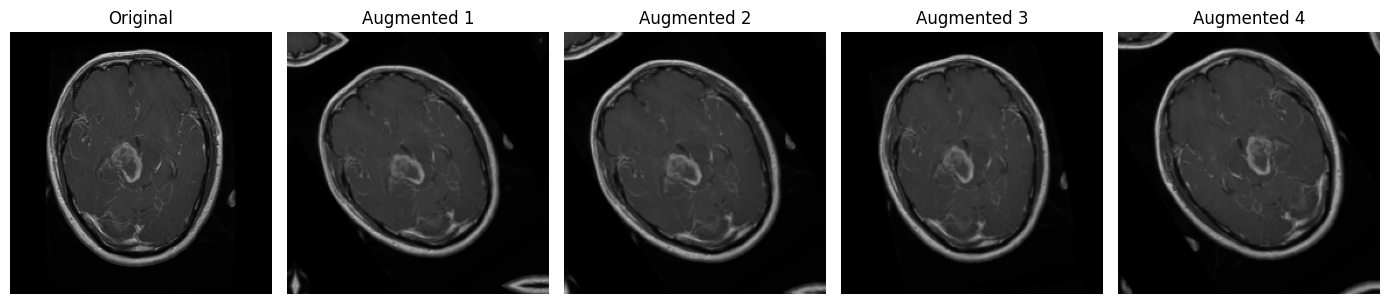

In [10]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="data_augmentation")


def make_dataset(df, training=False, shuffle=False):
    """Build a tf.data pipeline from a DataFrame of paths and labels."""
    ds = tf.data.Dataset.from_tensor_slices(
        (df["path"].values, df["label"].values.astype("int32"))
    )
    if shuffle:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (load_and_preprocess(p), y),
                num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if training:  # augmentation ONLY for training data
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)


train_dataset = make_dataset(train_df, training=True, shuffle=True)
validation_dataset = make_dataset(val_df)

# Show original vs augmented versions of one training image
sample = load_and_preprocess(train_df["path"].iloc[0])[tf.newaxis, ...]
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
axes[0].imshow(sample[0]); axes[0].set_title("Original")
for i in range(1, 5):
    axes[i].imshow(data_augmentation(sample, training=True)[0])
    axes[i].set_title(f"Augmented {i}")
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

## 10. Build CNN Model

A simple CNN built from scratch (no pretrained models):

- 3 × (**Conv2D → ReLU → MaxPooling**) blocks learn increasingly complex features (edges → textures → shapes)
- **Flatten** turns feature maps into a vector
- **Dense (ReLU)** combines the features
- **Dropout** randomly disables neurons during training to reduce overfitting
- **Dense (Softmax, 4 units)** outputs a probability for each class

**Input contract (important for later phases):** the model expects a float32 batch of shape `(N, 224, 224, 3)` with values already scaled to 0–1.

In [11]:
def build_cnn():
    return keras.Sequential([
        layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ], name="brain_tumor_cnn")


model = build_cnn()

## 11. Display Model Architecture

In [12]:
model.summary()

Model: "brain_tumor_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## 12. Compile Model

- **Adam optimizer:** adaptive learning rate; a reliable default that converges quickly.
- **Sparse categorical cross-entropy:** the standard loss for multi-class classification when labels are integers (0–3) rather than one-hot vectors.
- **Accuracy:** the fraction of correctly classified images; easy to interpret.

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

## 13. Train Model

Training uses the training dataset and checks the validation dataset after every epoch. **EarlyStopping** stops training if validation loss stops improving for 4 epochs and restores the best weights.

If a saved model already exists (and `FORCE_RETRAIN = False`), it is loaded instead, so re-running the notebook does not retrain.

In [14]:
history_df = None

if os.path.exists(MODEL_PATH) and not FORCE_RETRAIN:
    print(f"Found saved model at '{MODEL_PATH}'. Loading it (no retraining).")
    model = keras.models.load_model(MODEL_PATH)
    if os.path.exists(HISTORY_PATH):
        history_df = pd.read_csv(HISTORY_PATH)
    TRAINED_NOW = False
else:
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )
    history = model.fit(
        train_dataset,
        validation_data=validation_dataset,
        epochs=EPOCHS,
        callbacks=[early_stop],
    )
    history_df = pd.DataFrame(history.history)
    history_df.index.name = "epoch"
    history_df.to_csv(HISTORY_PATH)
    TRAINED_NOW = True
    print(f"Training history saved to '{HISTORY_PATH}'.")

Epoch 1/20


c:\Users\Vaishnav\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


72/72 ━━━━━━━━━━━━━━━━━━━━ 92s 1s/step - accuracy: 0.4599 - loss: 1.2578 - val_accuracy: 0.6167 - val_loss: 0.9969
Epoch 2/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 135s 1s/step - accuracy: 0.5645 - loss: 1.0064 - val_accuracy: 0.6742 - val_loss: 0.7429
Epoch 3/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 219s 3s/step - accuracy: 0.6376 - loss: 0.8679 - val_accuracy: 0.6882 - val_loss: 0.7360
Epoch 4/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.6773 - loss: 0.7760 - val_accuracy: 0.7108 - val_loss: 0.6563
Epoch 5/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 813s 11s/step - accuracy: 0.6790 - loss: 0.7429 - val_accuracy: 0.7160 - val_loss: 0.6698
Epoch 6/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 2249s 32s/step - accuracy: 0.7025 - loss: 0.7003 - val_accuracy: 0.7578 - val_loss: 0.5788
Epoch 7/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 103s 1s/step - accuracy: 0.7382 - loss: 0.6426 - val_accuracy: 0.7578 - val_loss: 0.5538
Epoch 8/20
72/72 ━━━━━━━━━━━━━━━━━━━━ 108s 1s/step - accuracy: 0.7369 - loss: 0.6240 - val_accuracy: 0.7927 - val_loss: 0

## 14. Plot Training/Validation Accuracy

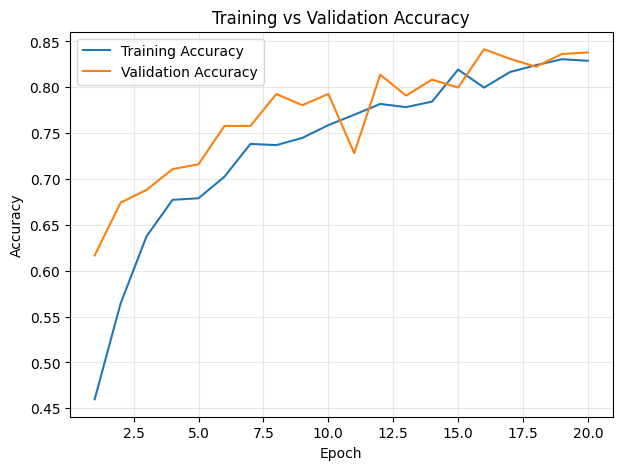

In [15]:
if history_df is None:
    print("No training history available (retrain with FORCE_RETRAIN = True to create one).")
else:
    epochs_range = range(1, len(history_df) + 1)
    plt.figure(figsize=(7, 5))
    plt.plot(epochs_range, history_df["accuracy"], label="Training Accuracy")
    plt.plot(epochs_range, history_df["val_accuracy"], label="Validation Accuracy")
    plt.xlabel("Epoch"); plt.ylabel("Accuracy")
    plt.title("Training vs Validation Accuracy")
    plt.legend(); plt.grid(alpha=0.3)
    plt.savefig(os.path.join(RESULTS_DIR, "accuracy_plot.png"), dpi=120)
    plt.show()

## 15. Plot Training/Validation Loss

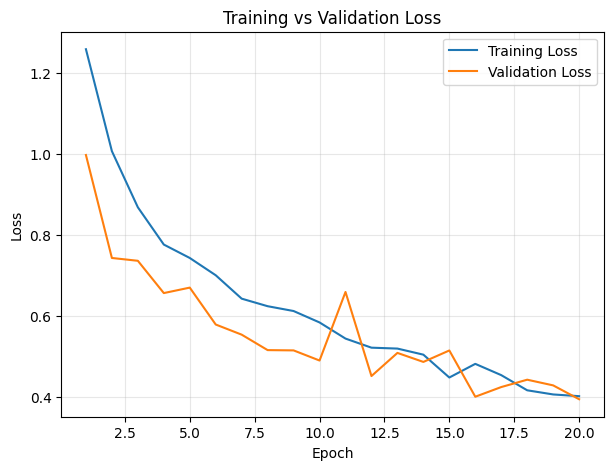

In [16]:
if history_df is not None:
    plt.figure(figsize=(7, 5))
    plt.plot(epochs_range, history_df["loss"], label="Training Loss")
    plt.plot(epochs_range, history_df["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title("Training vs Validation Loss")
    plt.legend(); plt.grid(alpha=0.3)
    plt.savefig(os.path.join(RESULTS_DIR, "loss_plot.png"), dpi=120)
    plt.show()

**How to read these graphs**

- Both accuracy curves rising and both loss curves falling means the model is learning.
- If training accuracy keeps rising while validation accuracy stalls (or validation loss rises), the model is **overfitting**: memorizing the training images instead of generalizing.
- A small gap between training and validation curves is healthy.

## 16. Evaluate Model on Testing Dataset

This is the first and only time the **Testing** folder is used. The data is not shuffled, so predictions line up with the true labels.

In [17]:
test_dataset = make_dataset(test_df)  # no augmentation, no shuffling

test_loss, test_accuracy = model.evaluate(test_dataset, verbose=1)
print(f"\nTest Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

test_probs = model.predict(test_dataset, verbose=0)
y_pred = np.argmax(test_probs, axis=1)
y_true = test_df["label"].values

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - accuracy: 0.5609 - loss: 3.4576

Test Loss:     3.4576
Test Accuracy: 56.09%


## 17. Classification Report

In [18]:
target_names = [DISPLAY_NAMES[c] for c in CLASS_NAMES]
print(classification_report(y_true, y_pred, target_names=target_names, digits=4))

report_df = pd.DataFrame(
    classification_report(y_true, y_pred, target_names=target_names, output_dict=True)
).transpose()
report_df.to_csv(os.path.join(RESULTS_DIR, "classification_report.csv"))
report_df.round(4)

              precision    recall  f1-score   support

      Glioma     1.0000    0.1200    0.2143       100
  Meningioma     0.5847    0.6000    0.5923       115
    No Tumor     0.4541    0.9429    0.6130       105
   Pituitary     0.8913    0.5541    0.6833        74

    accuracy                         0.5609       394
   macro avg     0.7325    0.5542    0.5257       394
weighted avg     0.7129    0.5609    0.5190       394



,precision,recall,f1-score,support
Glioma,1.0000,0.1200,0.2143,100.0000
Meningioma,0.5847,0.6000,0.5923,115.0000
No Tumor,0.4541,0.9429,0.6130,105.0000
Pituitary,0.8913,0.5541,0.6833,74.0000
accuracy,0.5609,0.5609,0.5609,0.5609
macro avg,0.7325,0.5542,0.5257,394.0000
weighted avg,0.7129,0.5609,0.5190,394.0000


- **Precision:** of the images predicted as a class, how many were correct.
- **Recall:** of the images truly in a class, how many were found.
- **F1-score:** the balance of precision and recall.
- **Support:** number of test images in that class.

## 18. Confusion Matrix

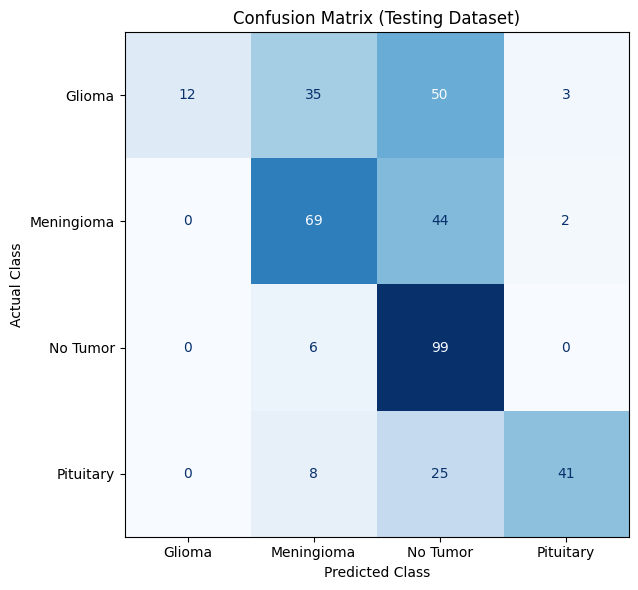

In [19]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False
)
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
ax.set_title("Confusion Matrix (Testing Dataset)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=120)
plt.show()

**How to interpret the matrix**

- Rows are the **actual** class; columns are the **predicted** class.
- The diagonal holds correct predictions; larger diagonal numbers are better.
- Off-diagonal numbers are mistakes. For example, a value in row *Glioma*, column *Meningioma* means glioma images that were wrongly predicted as meningioma.
- A tumor image predicted as *No Tumor* is the most serious kind of error for a detection system.

## 19. Individual MRI Prediction

`predict_mri(image_path)` is a reusable function that applies the **same preprocessing** used in training, runs the CNN and returns the class probabilities, predicted class, confidence and detection status. Prediction never triggers retraining.

In [20]:
def predict_mri(image_path, model=model):
    """Predict tumor status/type for one MRI image.

    Returns a dict with: status, tumor_detected, tumor_type, prediction,
    confidence (percent) and probabilities (percent per class).
    """
    if not os.path.isfile(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")
    try:
        with Image.open(image_path) as im:
            im.verify()
    except Exception as e:
        raise ValueError(f"Invalid or corrupt image: {image_path}") from e

    # Steps 1-4: load, convert to RGB, resize 224x224, normalize 0-1 (shared function)
    image = load_and_preprocess(image_path)
    # Step 5: add batch dimension
    batch = tf.expand_dims(image, axis=0)
    # Steps 6-7: forward pass -> softmax probabilities
    probs = model.predict(batch, verbose=0)[0]
    # Steps 8-9: predicted class and confidence
    pred_idx = int(np.argmax(probs))
    pred_class = CLASS_NAMES[pred_idx]
    confidence = float(probs[pred_idx]) * 100

    # Tumor detection logic (same 4-class CNN, no separate binary model)
    if pred_class == "no_tumor":
        tumor_detected, status, tumor_type = False, "No Tumor Detected", None
    else:
        tumor_detected, status, tumor_type = True, "Tumor Detected", DISPLAY_NAMES[pred_class]

    return {
        "image_path": image_path,
        "status": status,
        "tumor_detected": tumor_detected,
        "tumor_type": tumor_type,
        "prediction": DISPLAY_NAMES[pred_class],
        "confidence": confidence,
        "probabilities": {DISPLAY_NAMES[c]: float(p) * 100 for c, p in zip(CLASS_NAMES, probs)},
    }


def show_prediction(result):
    """Print and display a prediction result in the report format."""
    print("=" * 32)
    print("Brain Tumor Classification")
    print("=" * 32)
    print(f"\nImage: {os.path.basename(result['image_path'])}\n")
    print(f"Status:\n{result['status']}\n")
    if result["tumor_detected"]:
        print(f"Tumor Type:\n{result['tumor_type']}\n")
    else:
        print(f"Prediction:\n{result['prediction']}\n")
    print(f"Confidence:\n{result['confidence']:.2f}%\n")
    print("Class Probabilities:\n")
    for name, p in result["probabilities"].items():
        print(f"{name:<12} {p:6.2f}%")
    print("\nNote: educational project only, not a medical diagnosis.")

    plt.figure(figsize=(4, 4))
    plt.imshow(Image.open(result["image_path"]).convert("RGB"))
    plt.axis("off")
    plt.title(f"{result['prediction']} ({result['confidence']:.1f}%)")
    plt.show()

Choose an image to test. By default we use the first image from the Testing folder; replace `IMAGE_PATH` with the path to any MRI image.

In [21]:
IMAGE_PATH = test_df["path"].iloc[0]   # <- change this to your own MRI image path
print("Using image:", IMAGE_PATH)
result = predict_mri(IMAGE_PATH)

Using image: dataset\Testing\glioma_tumor\image(1).jpg


## 20. Tumor Detection Result

In [22]:
print("Status:", result["status"])
print("Tumor detected:", result["tumor_detected"])

Status: No Tumor Detected
Tumor detected: False


## 21. Tumor Type Prediction

In [23]:
if result["tumor_detected"]:
    print("Tumor Type:", result["tumor_type"])
else:
    print("No tumor type: the model predicts 'No Tumor' for this image.")

No tumor type: the model predicts 'No Tumor' for this image.


## 22. Confidence Score

Brain Tumor Classification

Image: image(1).jpg

Status:
No Tumor Detected

Prediction:
No Tumor

Confidence:
54.97%

Class Probabilities:

Glioma         0.00%
Meningioma    44.99%
No Tumor      54.97%
Pituitary      0.04%

Note: educational project only, not a medical diagnosis.


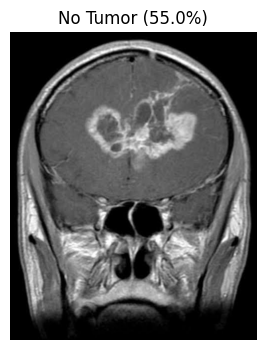

In [24]:
show_prediction(result)

## 23. Save Trained Model

The model is saved to `models/brain_tumor_cnn.keras`. The class order is saved alongside it in `models/class_names.json` so the future Streamlit app and segmentation-integrated system use the same label mapping.

In [25]:
if TRAINED_NOW:
    model.save(MODEL_PATH)
    print(f"Model saved to '{MODEL_PATH}'")
else:
    print(f"Model was loaded from '{MODEL_PATH}'; no need to save again.")

with open(CLASS_NAMES_PATH, "w") as f:
    json.dump({
        "class_names": CLASS_NAMES,
        "display_names": DISPLAY_NAMES,
        "img_size": list(IMG_SIZE),
        "preprocessing": "RGB, resize to 224x224, divide by 255.0 (float32, range 0-1)",
    }, f, indent=2)
print(f"Class metadata saved to '{CLASS_NAMES_PATH}'")

# Verify the saved file loads and gives identical predictions
reloaded = keras.models.load_model(MODEL_PATH)
check = reloaded.predict(tf.expand_dims(load_and_preprocess(IMAGE_PATH), 0), verbose=0)[0]
print("Reload check OK. Max probability:", f"{check.max() * 100:.2f}%")

Model saved to 'models\brain_tumor_cnn.keras'
Class metadata saved to 'models\class_names.json'
Reload check OK. Max probability: 54.97%


## 24. Final Conclusion

**Summary**

- A simple 3-block CNN was trained from scratch on brain MRI images to classify them as glioma, meningioma, pituitary tumor or no tumor.
- The Training folder was split 80/20 into training and validation sets; the Testing folder was kept untouched until final evaluation.
- Results were assessed with test accuracy, a classification report (precision, recall, F1, support), a confusion matrix, and accuracy/loss curves.
- `predict_mri()` returns tumor detection status, tumor type, confidence and all class probabilities for a single image.
- The model and class mapping are saved in `models/` for reuse.

**Limitations**

- The model is trained on one dataset; performance may drop on MRI scans from other scanners, hospitals or imaging protocols.
- A simple CNN has limited capacity, and confidence scores from softmax can be overconfident.
- The model works on single 2D images and gives no tumor location or size.

**Future work (next phase)**

Segmentation will be added as a separate component that runs alongside this CNN on the same preprocessed MRI. This classification model stays unchanged and independent, and both will later be combined in a Streamlit application.

> ### Medical Disclaimer
> This project is for **academic and educational purposes only**. The model's output is **not a medical diagnosis** and must never replace the judgment of a qualified doctor or radiologist. Do not use it for any clinical decision.